<a href="https://colab.research.google.com/github/yamenetoo/Statistical-Repository/blob/main/Else/DLE1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Statistical Pruning of a One-Hidden-Layer Neural Network

A binary classifier with one hidden layer is a logistic regression whose regressors are the hidden activations. That view allows ordinary descriptive statistics to decide which hidden units are unnecessary.

**Procedure**

1. Train a baseline network (`HL = 16` ReLU units) on a two-class subset of Iris.
2. Collect the hidden activations as a data matrix (samples × units) and inspect them.
3. **Dead units** (zero variance, always output 0): remove them. The function of the network is unchanged.
4. **Redundant units** (pairwise |correlation| above a threshold): keep one representative of each correlated group.
5. Transfer the surviving weights to a smaller network, compare predictions, and fine-tune.

**Contents**: 1 Setup · 2 Helper functions · 3 Data and baseline model · 4 Hidden-layer diagnostics · 5 Remove dead units · 6 Remove correlated units · 7 Fine-tune the pruned network · 8 Comparison

## 1. Setup

In [1]:
# Optional, only needed for the architecture diagrams:  !pip install plot-ann
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

try:
    from plot_ann import ann
except ImportError:          # diagrams are skipped when the package is missing
    ann = None

# ---- Configuration -------------------------------------------------------
SEED = 42
BINARY_CLASSES = (0, 1)      # Iris: setosa vs versicolor
TEST_SIZE = 0.2
HIDDEN_UNITS = 16
BATCH_SIZE = 1
EPOCHS_BASE = 10
EPOCHS_FINE_TUNE = 25
DEAD_STD_TOL = 1e-8          # a unit is "dead" when its activation std is below this
CORR_THRESHOLD = 0.7         # |r| above this marks two units as redundant

tf.keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel("ERROR")      # silence retracing notices
pd.set_option("display.precision", 4)

## 2. Helper functions

In [2]:
def build_model(n_features: int, n_hidden: int) -> keras.Model:
    """Input -> Dense(n_hidden, ReLU, name="HL") -> Dense(1, sigmoid, name="OL")."""
    model = keras.Sequential([
        layers.Input(shape=(n_features,), name="input_layer"),
        layers.Dense(n_hidden, activation="relu", name="HL"),
        layers.Dense(1, activation="sigmoid", name="OL"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


def hidden_activations(model: keras.Model, X: np.ndarray) -> np.ndarray:
    """Return the output of the hidden layer "HL" (shape: samples x units)."""
    probe = keras.Model(model.inputs, model.get_layer("HL").output)
    return probe.predict(X, verbose=0)


def find_dead_units(acts: np.ndarray, tol: float = DEAD_STD_TOL) -> np.ndarray:
    """Indices of units whose activation has (numerically) zero variance."""
    return np.flatnonzero(acts.std(axis=0, ddof=1) <= tol)


def select_uncorrelated_units(acts: np.ndarray, candidates: np.ndarray,
                              threshold: float = CORR_THRESHOLD) -> np.ndarray:
    """Greedy filter: scan the candidate units in order and keep a unit only if its
    |correlation| with every unit already kept is at most `threshold`."""
    corr = np.corrcoef(acts[:, candidates], rowvar=False)
    kept = []
    for i in range(len(candidates)):
        if all(abs(corr[i, j]) <= threshold for j in kept):
            kept.append(i)
    return candidates[kept]


def prune_hidden_units(model: keras.Model, keep: np.ndarray) -> keras.Model:
    """Build a smaller network that keeps only the hidden units in `keep` (0-based).

    For every kept unit the incoming weights (a column of the first kernel), its bias,
    and its outgoing weight (a row of the output kernel) are copied unchanged.
    """
    keep = np.asarray(keep, dtype=int)
    w_hidden, b_hidden, w_out, b_out = model.get_weights()
    pruned = build_model(w_hidden.shape[0], len(keep))
    pruned.set_weights([w_hidden[:, keep], b_hidden[keep], w_out[keep, :], b_out])
    return pruned


def summarise(model: keras.Model, name: str, X_test: np.ndarray, y_test: np.ndarray) -> dict:
    """One row of the comparison table."""
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    return {"model": name,
            "hidden units": model.get_layer("HL").units,
            "parameters": model.count_params(),
            "test loss": loss,
            "test accuracy": acc}


def draw_architecture(n_inputs: int, n_hidden: int, title: str) -> None:
    """Network diagram (needs the optional `plot-ann` package)."""
    if ann is None:
        return
    ax, *_ = ann([n_inputs, n_hidden, 1], layer_labels=["Input", "HL", "Output"])
    ax.set_aspect("equal")
    ax.set_title(title)
    plt.show()

In [3]:
def plot_activation_boxplots(acts: np.ndarray) -> None:
    labels = [f"HL_{i}" for i in range(acts.shape[1])]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.boxplot(acts)
    ax.set_xticklabels(labels)
    ax.set_ylabel("Activation")
    ax.set_title(f"Hidden-unit activations ({acts.shape[1]} units)")
    ax.tick_params(axis="x", rotation=90)
    plt.show()


def plot_correlation_matrix(acts: np.ndarray, labels=None, title="Correlation of hidden activations") -> None:
    corr = pd.DataFrame(acts, columns=labels).corr()
    fig, ax = plt.subplots(figsize=(8, 6))
    image = ax.matshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    fig.colorbar(image, ax=ax)
    for i in range(len(corr)):
        for j in range(len(corr)):
            value = corr.iloc[i, j]
            ax.text(j, i, "n/a" if np.isnan(value) else f"{value:.2f}",
                    ha="center", va="center", fontsize=7)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)), corr.columns)
    ax.set_title(title, pad=40)
    plt.show()


def plot_unit_scatter(acts: np.ndarray, i: int, j: int, y: np.ndarray, labels) -> None:
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.scatter(acts[:, i], acts[:, j], c=np.where(y == 0, "tab:red", "tab:blue"), s=18)
    ax.set_xlabel(f"unit {labels[i]}")
    ax.set_ylabel(f"unit {labels[j]}")
    ax.set_title("Class separation in the retained units (red = class 0, blue = class 1)")
    plt.show()

## 3. Data and baseline model

Iris is restricted to the two linearly separable classes (setosa and versicolor): 100 samples, 4 features, split 80 / 20.

train: (80, 4)   test: (20, 4)


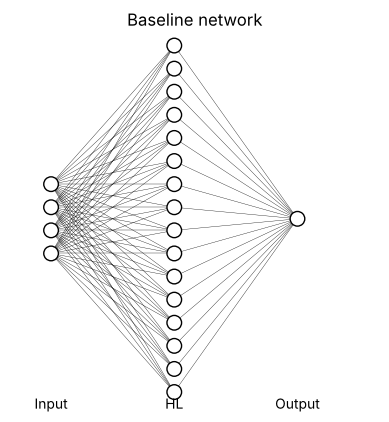

final training loss 0.0474, accuracy 1.0000


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ HL (Dense)                      │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ OL (Dense)                      │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 293 (1.15 KB)

 Trainable params: 97 (388.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 196 (788.00 B)

In [4]:
iris = load_iris()
mask = np.isin(iris.target, BINARY_CLASSES)
X, y = iris.data[mask], iris.target[mask]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)
print(f"train: {X_train.shape}   test: {X_test.shape}")

model_full = build_model(X_train.shape[1], HIDDEN_UNITS)
draw_architecture(X_train.shape[1], HIDDEN_UNITS, "Baseline network")
history = model_full.fit(X_train, y_train, epochs=EPOCHS_BASE, batch_size=BATCH_SIZE, verbose=0)
print(f"final training loss {history.history['loss'][-1]:.4f}, "
      f"accuracy {history.history['accuracy'][-1]:.4f}")
model_full.summary()

## 4. Hidden-layer diagnostics

The activations of all 100 samples form a 100 × 16 matrix. Its column statistics and correlation matrix drive the pruning decisions.

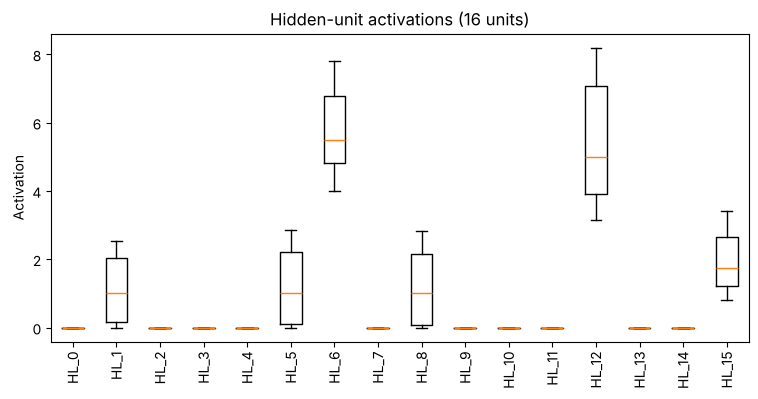

,count,mean,std,min,25%,50%,75%,max
0,100.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,100.0,1.1056,0.9633,0.0000,0.1649,1.0150,2.0338,2.5434
2,100.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,100.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,100.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
5,100.0,1.1726,1.0757,0.0000,0.1021,1.0189,2.2126,2.8642
6,100.0,5.7832,1.1211,4.0030,4.8073,5.4864,6.7916,7.8011
7,100.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
8,100.0,1.1476,1.0536,0.0000,0.0910,1.0115,2.1435,2.8157
9,100.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [5]:
acts_full = hidden_activations(model_full, X)
unit_labels = list(range(acts_full.shape[1]))
plot_activation_boxplots(acts_full)
pd.DataFrame(acts_full, columns=unit_labels).describe().T

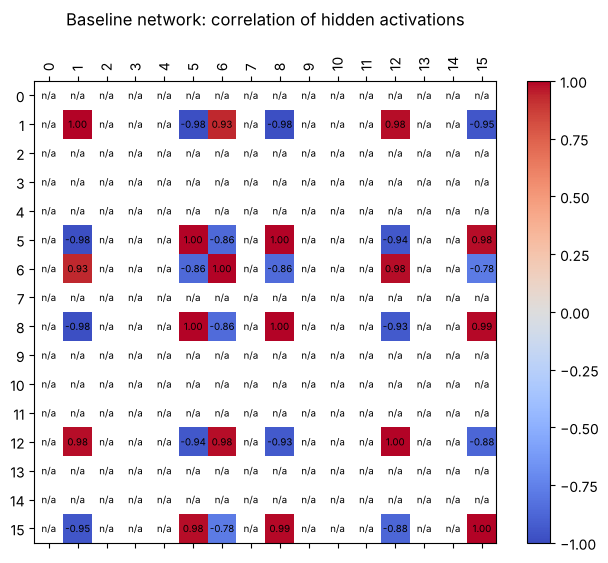

In [6]:
plot_correlation_matrix(acts_full, labels=unit_labels, title="Baseline network: correlation of hidden activations")

## 5. Remove dead units

A ReLU unit whose output is 0 for every sample contributes nothing to the output layer, so deleting it (with its bias and outgoing weight) leaves the function unchanged.

dead units (10): [0, 2, 3, 4, 7, 9, 10, 11, 13, 14]
remaining units (6): [1, 5, 6, 8, 12, 15]


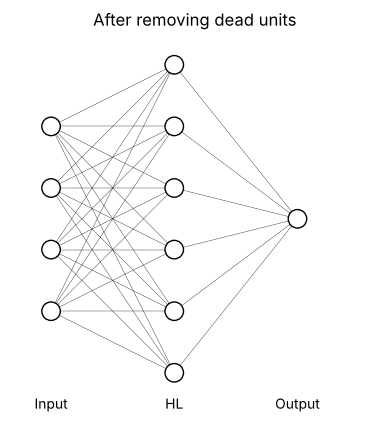

max |prediction difference| on the test set: 1.49e-08


In [7]:
dead = find_dead_units(acts_full)
alive = np.setdiff1d(np.arange(HIDDEN_UNITS), dead)
print(f"dead units ({len(dead)}): {dead.tolist()}")
print(f"remaining units ({len(alive)}): {alive.tolist()}")

model_alive = prune_hidden_units(model_full, alive)
draw_architecture(X_train.shape[1], len(alive), "After removing dead units")

# Equivalence check: predictions must match the baseline
p_full = model_full.predict(X_test, verbose=0).ravel()
p_alive = model_alive.predict(X_test, verbose=0).ravel()
print(f"max |prediction difference| on the test set: {np.abs(p_full - p_alive).max():.2e}")

## 6. Remove correlated units

Among the surviving units, a unit is redundant when it is strongly correlated (|r| above the threshold) with a unit that has already been kept. The filter scans the units in order and keeps one representative per correlated group.

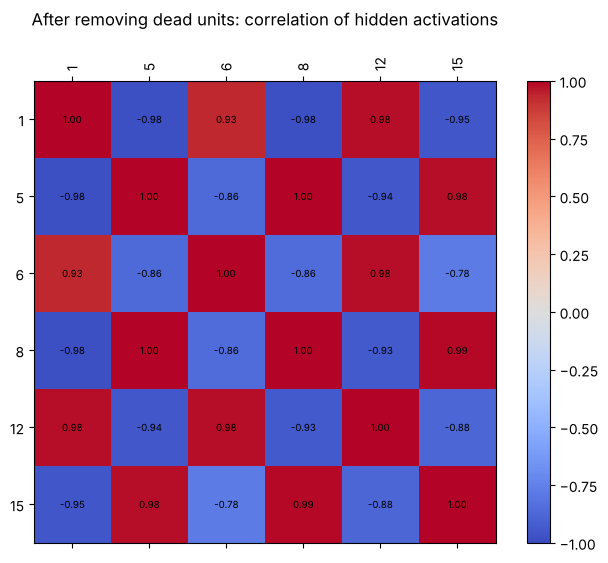

In [8]:
acts_alive = hidden_activations(model_alive, X)       # columns follow `alive`
plot_correlation_matrix(acts_alive, labels=alive.tolist(),
                        title="After removing dead units: correlation of hidden activations")

threshold |r| > 0.7
kept units (index in the baseline network): [1]


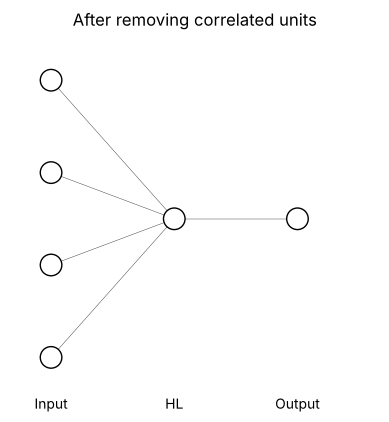

,count,mean,std,min,25%,50%,75%,max
1,100.0,1.1056,0.9633,0.0,0.1649,1.015,2.0338,2.5434


In [9]:
kept_local = select_uncorrelated_units(acts_alive, np.arange(len(alive)), CORR_THRESHOLD)
kept_original = alive[kept_local]            # index of each kept unit in the baseline network
print(f"threshold |r| > {CORR_THRESHOLD}")
print(f"kept units (index in the baseline network): {kept_original.tolist()}")

model_small = prune_hidden_units(model_alive, kept_local)
draw_architecture(X_train.shape[1], len(kept_local), "After removing correlated units")
acts_small = hidden_activations(model_small, X)
pd.DataFrame(acts_small, columns=kept_original.tolist()).describe().T

In [10]:
if acts_small.shape[1] >= 2:
    order = np.argsort(acts_small.var(axis=0))[::-1][:2]
    plot_unit_scatter(acts_small, order[0], order[1], y, kept_original)

**Single-unit logistic regression.** The unit with the largest variance is used as the only regressor of a logistic regression (with intercept) to see how much of the class information it carries alone. For well separated classes the maximum-likelihood estimate may not exist; the cell reports this instead of failing.

In [11]:
best = int(np.argmax(acts_small.var(axis=0)))
design = sm.add_constant(acts_small[:, best])
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    try:
        fit = sm.Logit(y, design).fit(disp=False)
        separated = (not fit.mle_retvals["converged"]) or any("separation" in str(w.message).lower() for w in caught)
    except Exception as exc:                      # e.g. PerfectSeparationError
        fit, separated = None, True
print(f"regressor: baseline unit {kept_original[best]}")
if separated:
    print("The classes are perfectly separated by this single unit, so the maximum-likelihood "
          "estimate does not exist (coefficients diverge).")
else:
    print(fit.summary())

regressor: baseline unit 1
The classes are perfectly separated by this single unit, so the maximum-likelihood estimate does not exist (coefficients diverge).


## 7. Fine-tune the pruned network

Removing correlated units changes the function, so the predictions right after the weight transfer differ from the baseline. A short fine-tuning run recovers the fit.

In [12]:
p_small_before = model_small.predict(X_test, verbose=0).ravel()
before = summarise(model_small, "pruned (before fine-tuning)", X_test, y_test)

model_small.fit(X_train, y_train, epochs=EPOCHS_FINE_TUNE, batch_size=BATCH_SIZE, verbose=0)
p_small_after = model_small.predict(X_test, verbose=0).ravel()

pd.DataFrame({"y_test": y_test,
              "baseline": p_full,
              "no dead units": p_alive,
              "pruned, before": p_small_before,
              "pruned, fine-tuned": p_small_after}).round(4)

,y_test,baseline,no dead units,"pruned, before","pruned, fine-tuned"
0,1,0.9893,0.9893,0.7288,0.9928
1,1,0.9749,0.9749,0.6947,0.9764
2,1,0.9852,0.9852,0.7145,0.9897
3,0,0.0689,0.0689,0.5286,0.3026
4,0,0.0543,0.0543,0.5205,0.3029
5,0,0.0392,0.0392,0.5142,0.3026
6,0,0.0151,0.0151,0.4970,0.3026
7,1,0.9597,0.9597,0.6752,0.9587
8,0,0.0247,0.0247,0.5080,0.3026
9,0,0.0291,0.0291,0.5074,0.3026


## 8. Comparison

In [13]:
rows = [summarise(model_full, "baseline", X_test, y_test),
        summarise(model_alive, "dead units removed", X_test, y_test),
        before,
        summarise(model_small, "pruned + fine-tuned", X_test, y_test)]
comparison = pd.DataFrame(rows).set_index("model")
comparison

,hidden units,parameters,test loss,test accuracy
model,,,,
baseline,16,97,0.0322,1.0
dead units removed,6,37,0.0322,1.0
pruned (before fine-tuning),1,7,0.5721,0.5
pruned + fine-tuned,1,7,0.2244,1.0
